# Dynamic Model in Levels (EmbeddingGemma 2 embeddings)

Re-run of `04_evaluation.ipynb` in which the fine-tuned (DoubleMLDeep) product embeddings are replaced by off-the-shelf embeddings from [EmbeddingGemma 2](https://huggingface.co/google/embeddinggemma-2) (`google/embeddinggemma-2`).

All embedding-derived variables (`emb_*`, `pca_*`, `similarity_cluster_*`) are recomputed from the EmbeddingGemma 2 embeddings (`01_3_compute_embeddings_gemma.ipynb`, `01_4_create_dataset_gemma.ipynb`); all other variables and the estimation sample are identical to the main analysis. Apart from the parameters below, the output directory, and the export of the key results at the end, the notebook is identical to `04_evaluation.ipynb`.

Main specification: text + image embeddings truncated to 256 dimensions (Matryoshka), i.e. the same dimension as the fine-tuned embeddings.

In [1]:
# Embeddings used for emb_*, pca_* and similarity_cluster_*
embedding_source = "embeddinggemma2"  # "embeddinggemma2" | "finetuned" (fine-tuned embeddings, as in 04_evaluation.ipynb)
modality = "txtimg"  # EmbeddingGemma 2 input: "txtimg" (text + image) | "txt" (text only)
emb_dim = 768  # EmbeddingGemma 2 Matryoshka dimension: 768 | 256

In [2]:
import os
import datasets
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score

import doubleml as dml

from utils.utils_data2 import (
    get_cis,
    generate_basis,
    generate_interactions,
)

from utils.utils_models import (
    iv_model,
    lin_model,
    lin_model_cate,
    summarize_lin_model,
    summarize_dml,
    chi2_test,
    predict_cate,
)
import warnings
warnings.filterwarnings("ignore")

# Get a colorblind-friendly palette
palette = sns.color_palette("colorblind")

confidence_level = 0.9
ci_level_name, ci_names = get_cis(confidence_level)

run_name = (
    "finetuned"
    if embedding_source == "finetuned"
    else f"embeddinggemma2_{modality}_dim{emb_dim}"
)
output_dir = f"../output/04_evaluation_gemma/{run_name}"
Path(output_dir).mkdir(parents=True, exist_ok=True)

/tmp/claude-0/-home-user-demand-analysis-repro/8871aba3-e06d-5440-87b8-bf4072e29cf1/scratchpad/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Confidence Level: 90.0%


In [3]:
txt_only = False
include_embeddings = True
if embedding_source == "finetuned":
    dataframe_name = f"dataset_txt_only_{txt_only}_embeddings_{include_embeddings}"
else:
    dataframe_name = f"dataset_gemma_{modality}_dim{emb_dim}"
df_full_train = pd.read_csv(f"../data/{dataframe_name}_train.zip")
df_full_val = pd.read_csv(f"../data/{dataframe_name}_val.zip")

columns_to_drop = [
    "Q_t-2",
    "P_bb_t-2",
    "REVIEW_COUNT_t-2",
    "RATING_t-2",
    "pred_ml_l_lag_1",
    "pred_ml_m_lag_1",
]


df_full_train = df_full_train.drop(columns=columns_to_drop)
df_full_val = df_full_val.drop(columns=columns_to_drop)

df_full_train = df_full_train.dropna()
df_full_val = df_full_val.dropna()

dummy_subcat_names = [
    category for category in df_full_val["subcat_aggregated"].unique()
]
all_time_steps = sorted([str(date) for date in df_full_val["date"].unique()])

print(f"Dummy subcat names: {dummy_subcat_names}")
print(f"All time steps: {all_time_steps}")
df_full_val.columns

Dummy subcat names: ['Residual', 'Cars & Race Cars', 'Trains & Trams', 'Train Sets', 'Trucks', 'Tractors', 'Race Tracks', 'Airplanes', 'Motor Vehicles', 'Vehicle Playsets', 'Skateboards']
All time steps: ['2023-02-27', '2023-03-27', '2023-04-24', '2023-05-22', '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11', '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01', '2024-01-29']


Index(['ASIN', 'date', 'index', 'Q_t', 'PRICE', 'P_bb_t', 'text', 'window',
       'REVIEW_COUNT', 'RATING',
       ...
       'REVIEW_COUNT_t-1', 'RATING_t-1', 'Delta_Q_t', 'Delta_P_bb_t',
       'pred_ml_l', 'pred_ml_m', 'pred_ml_l_diff', 'pred_ml_m_diff',
       'pred_ml_l_diff_lag_1', 'pred_ml_m_diff_lag_1'],
      dtype='object', length=854)

In [4]:
print(dataframe_name)

dataset_gemma_txtimg_dim768


In [5]:
print(df_full_val.shape)
print(df_full_train.shape)

(38041, 854)
(38146, 854)


In [6]:
# same estimation sample as in the main analysis (keys written by 04_evaluation.ipynb)
assert df_full_val[["ASIN", "date"]].reset_index(drop=True).equals(pd.read_csv("main_val_keys.csv"))
assert df_full_train[["ASIN", "date"]].reset_index(drop=True).equals(pd.read_csv("main_train_keys.csv"))

In [7]:
df_full_val.isna().sum()

ASIN                    0
date                    0
index                   0
Q_t                     0
PRICE                   0
                       ..
pred_ml_m               0
pred_ml_l_diff          0
pred_ml_m_diff          0
pred_ml_l_diff_lag_1    0
pred_ml_m_diff_lag_1    0
Length: 854, dtype: int64

In [8]:
df_full_train["date"].unique()

array(['2023-02-27', '2023-03-27', '2023-04-24', '2023-05-22',
       '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11',
       '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01',
       '2024-01-29'], dtype=object)

In [9]:
df_full_val["date"].unique()

array(['2023-02-27', '2023-03-27', '2023-04-24', '2023-05-22',
       '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11',
       '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01',
       '2024-01-29'], dtype=object)

In [10]:
df_full_train["ASIN"].nunique()

3717

In [11]:
df_full_val["ASIN"].nunique()

3708

In [12]:
from datetime import datetime

date_objects = [datetime.strptime(date, "%Y-%m-%d") for date in all_time_steps]

# Calculate the difference in days between consecutive dates
date_differences = [
    (date_objects[i + 1] - date_objects[i]).days for i in range(len(date_objects) - 1)
]

# Print the differences
print(date_differences)

[28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28]


## Variable Names

In [13]:
n_lags = 1

outcome = ["Q_t"]
base_treatment = ["P_bb_t"]
lag_1_vars = ["Q_t-1", "P_bb_t-1"]

dummy_time_steps = all_time_steps[n_lags:]

all_dummy_controls = (
    dummy_subcat_names
    + dummy_time_steps
    + [
        "Lightning Deals: Upcoming Deal",
        "Buy Box: Is FBA",
    ]
)
dummy_baselines = [dummy_time_steps[0], "Residual"]
dummy_time_steps_wo_baseline = [t for t in dummy_time_steps if t not in dummy_baselines]
dummy_controls = [t for t in all_dummy_controls if t not in dummy_baselines]

cont_controls = [
    "RATING_t-1",
    "REVIEW_COUNT_t-1",
    "New Offer Count: Current",
    "Count of retrieved live offers: New, FBA",
    "Count of retrieved live offers: New, FBM",
]

add_controls_to_scale = [
    "RATING",
    "REVIEW_COUNT",
]

controls_pca = ["pca_0", "pca_1", "pca_2", "pca_3", "pca_4"]
controls_similarities = [
    "similarity_cluster_0",
    "similarity_cluster_1",
    "similarity_cluster_2",
    "similarity_cluster_3",
    "similarity_cluster_4",
]

n_embeddings = 256 if embedding_source == "finetuned" else emb_dim
embeddings = [f"emb_{i}" for i in range(n_embeddings)]
assert set(embeddings) == {c for c in df_full_val.columns if c.startswith("emb_")}

controls_to_scale = cont_controls + add_controls_to_scale

additional_controls = cont_controls + dummy_controls

## Interactions & CATE Basis

In [14]:
basis_vars = controls_similarities + lag_1_vars
df_basis, column_transformer, column_dict = generate_basis(
    df=df_full_val,
    cols_without_scaling=controls_similarities,
    cols_to_scale=lag_1_vars,
    degree=1,
)
df_basis.head()

,intercept,Q_t-1,P_bb_t-1,similarity_cluster_0,similarity_cluster_1,similarity_cluster_2,similarity_cluster_3,similarity_cluster_4
0,1.0,0.305280,0.463601,-0.146555,-0.116269,0.169582,-0.002445,0.051579
1,1.0,0.272505,0.653600,-0.146555,-0.116269,0.169582,-0.002445,0.051579
2,1.0,0.036240,0.687961,-0.146555,-0.116269,0.169582,-0.002445,0.051579
3,1.0,0.025283,0.636881,-0.146555,-0.116269,0.169582,-0.002445,0.051579
4,1.0,-0.051370,0.556816,-0.146555,-0.116269,0.169582,-0.002445,0.051579


In [15]:
df_interact_val, interaction_vars = generate_interactions(
    df=df_full_val, df_basis=df_basis, cols_to_interact=["Q_t-1", "P_bb_t-1"]
)

print(f"Interactions: {interaction_vars}")
df_interact_val.columns

Interactions: ['interaction_Q_t-1_intercept', 'interaction_Q_t-1_Q_t-1', 'interaction_Q_t-1_P_bb_t-1', 'interaction_Q_t-1_similarity_cluster_0', 'interaction_Q_t-1_similarity_cluster_1', 'interaction_Q_t-1_similarity_cluster_2', 'interaction_Q_t-1_similarity_cluster_3', 'interaction_Q_t-1_similarity_cluster_4', 'interaction_P_bb_t-1_intercept', 'interaction_P_bb_t-1_Q_t-1', 'interaction_P_bb_t-1_P_bb_t-1', 'interaction_P_bb_t-1_similarity_cluster_0', 'interaction_P_bb_t-1_similarity_cluster_1', 'interaction_P_bb_t-1_similarity_cluster_2', 'interaction_P_bb_t-1_similarity_cluster_3', 'interaction_P_bb_t-1_similarity_cluster_4']


Index(['ASIN', 'date', 'index', 'Q_t', 'PRICE', 'P_bb_t', 'text', 'window',
       'REVIEW_COUNT', 'RATING',
       ...
       'interaction_Q_t-1_similarity_cluster_3',
       'interaction_Q_t-1_similarity_cluster_4',
       'interaction_P_bb_t-1_intercept', 'interaction_P_bb_t-1_Q_t-1',
       'interaction_P_bb_t-1_P_bb_t-1',
       'interaction_P_bb_t-1_similarity_cluster_0',
       'interaction_P_bb_t-1_similarity_cluster_1',
       'interaction_P_bb_t-1_similarity_cluster_2',
       'interaction_P_bb_t-1_similarity_cluster_3',
       'interaction_P_bb_t-1_similarity_cluster_4'],
      dtype='object', length=870)

## Average Effect

In [16]:
df_dynamic = df_interact_val.copy()

### Linear Models

In [17]:
def estimate_linear_model(controls):
    model = lin_model(
        df=df_dynamic,
        outcome=outcome,
        treatments=base_treatment,
        controls=controls,
        level=confidence_level,
        cov_type="cluster",
        cov_kwds={"groups": df_dynamic["ASIN"]},
    )
    return model

In [18]:
estimate_linear_model(controls=[])

Adjusted R^2: 0.0027
          coef  std err        t  P>|t|   [5.0%  95.0%]
const  -10.756    0.104 -103.858  0.000 -10.926 -10.586
P_bb_t  -0.111    0.033   -3.384  0.001  -0.164  -0.057


,lower,upper,coef
P_bb_t,-0.164462,-0.056884,-0.110673


In [19]:
estimate_linear_model(controls=embeddings)

Adjusted R^2: 0.5241
            coef  std err       t  P>|t|    [5.0%   95.0%]
const     -9.871    0.120 -82.379  0.000  -10.068   -9.674
P_bb_t    -0.414    0.039 -10.631  0.000   -0.479   -0.350
emb_0     18.218   36.186   0.503  0.615  -41.302   77.739
emb_1      4.512   41.144   0.110  0.913  -63.164   72.187
emb_2    -24.918   47.000  -0.530  0.596 -102.226   52.390
...          ...      ...     ...    ...      ...      ...
emb_763  -26.955   69.971  -0.385  0.700 -142.046   88.136
emb_764 -175.799   63.459  -2.770  0.006 -280.180  -71.419
emb_765   -4.133   82.037  -0.050  0.960 -139.071  130.806
emb_766   21.060   70.157   0.300  0.764  -94.338  136.458
emb_767   11.376   53.890   0.211  0.833  -77.265  100.017

[770 rows x 6 columns]


,lower,upper,coef
P_bb_t,-0.478578,-0.350327,-0.414452


In [20]:
estimate_linear_model(controls=additional_controls)

Adjusted R^2: 0.2213
                                            coef  std err       t  P>|t|  \
const                                    -11.961    0.233 -51.298  0.000   
P_bb_t                                    -0.225    0.031  -7.254  0.000   
RATING_t-1                                 0.222    0.047   4.710  0.000   
REVIEW_COUNT_t-1                           0.000    0.000   5.015  0.000   
New Offer Count: Current                  -0.015    0.006  -2.599  0.009   
Count of retrieved live offers: New, FBA   0.056    0.013   4.217  0.000   
Count of retrieved live offers: New, FBM  -0.033    0.008  -4.285  0.000   
Cars & Race Cars                           0.259    0.057   4.513  0.000   
Trains & Trams                             0.456    0.131   3.473  0.001   
Train Sets                                 0.422    0.077   5.454  0.000   
Trucks                                     0.464    0.064   7.291  0.000   
Tractors                                   0.399    0.131   3.042  

,lower,upper,coef
P_bb_t,-0.275748,-0.173807,-0.224778


In [21]:
estimate_linear_model(controls=additional_controls + embeddings)

Adjusted R^2: 0.5889
                             coef  std err       t  P>|t|    [5.0%   95.0%]
const                     -10.954    0.206 -53.266  0.000  -11.292  -10.615
P_bb_t                     -0.383    0.036 -10.754  0.000   -0.441   -0.324
RATING_t-1                  0.147    0.035   4.192  0.000    0.089    0.204
REVIEW_COUNT_t-1            0.000    0.000   5.861  0.000    0.000    0.000
New Offer Count: Current   -0.011    0.005  -2.245  0.025   -0.020   -0.003
...                           ...      ...     ...    ...      ...      ...
emb_763                    16.081   63.339   0.254  0.800  -88.102  120.264
emb_764                  -157.283   56.695  -2.774  0.006 -250.539  -64.028
emb_765                   -43.728   75.255  -0.581  0.561 -167.510   80.055
emb_766                    17.566   64.525   0.272  0.785  -88.569  123.701
emb_767                    32.886   49.161   0.669  0.504  -47.976  113.748

[798 rows x 6 columns]


,lower,upper,coef
P_bb_t,-0.441065,-0.324037,-0.382551


In [22]:
ci_linear_base_lagged = estimate_linear_model(controls=lag_1_vars)

Adjusted R^2: 0.8835
           coef  std err        t  P>|t|  [5.0%  95.0%]
const    -0.677    0.034  -19.935    0.0 -0.733  -0.621
P_bb_t   -0.690    0.040  -17.248    0.0 -0.756  -0.624
Q_t-1     0.936    0.003  321.411    0.0  0.931   0.941
P_bb_t-1  0.678    0.040   16.995    0.0  0.613   0.744


In [23]:
ci_linear_embeddings = estimate_linear_model(controls=lag_1_vars + embeddings)

Adjusted R^2: 0.8877
            coef  std err        t  P>|t|   [5.0%  95.0%]
const     -1.304    0.054  -24.105  0.000  -1.393  -1.215
P_bb_t    -0.666    0.040  -16.673  0.000  -0.732  -0.600
Q_t-1      0.864    0.005  171.530  0.000   0.856   0.873
P_bb_t-1   0.597    0.040   14.986  0.000   0.531   0.662
emb_0     -2.693    6.012   -0.448  0.654 -12.582   7.196
...          ...      ...      ...    ...     ...     ...
emb_763    0.228   11.617    0.020  0.984 -18.881  19.336
emb_764  -26.615   10.541   -2.525  0.012 -43.954  -9.276
emb_765   -3.741   13.492   -0.277  0.782 -25.933  18.452
emb_766    4.611   12.007    0.384  0.701 -15.138  24.360
emb_767   -1.565    9.264   -0.169  0.866 -16.803  13.673

[772 rows x 6 columns]


In [24]:
ci_linear_base_lagged_add_controls = estimate_linear_model(
    controls=lag_1_vars + additional_controls
)

Adjusted R^2: 0.8929
                                           coef  std err        t  P>|t|  \
const                                    -0.962    0.051  -18.978  0.000   
P_bb_t                                   -0.746    0.039  -18.956  0.000   
Q_t-1                                     0.925    0.003  279.493  0.000   
P_bb_t-1                                  0.722    0.039   18.383  0.000   
RATING_t-1                                0.030    0.007    4.621  0.000   
REVIEW_COUNT_t-1                          0.000    0.000    8.670  0.000   
New Offer Count: Current                 -0.001    0.001   -1.625  0.104   
Count of retrieved live offers: New, FBA  0.005    0.001    3.398  0.001   
Count of retrieved live offers: New, FBM -0.004    0.001   -3.797  0.000   
Cars & Race Cars                          0.020    0.006    3.371  0.001   
Trains & Trams                            0.052    0.014    3.754  0.000   
Train Sets                                0.032    0.008    4.069  

In [25]:
ci_linear_base_lagged_add_controls_emb = estimate_linear_model(
    controls=lag_1_vars + additional_controls + embeddings
)

Adjusted R^2: 0.8965
              coef  std err        t  P>|t|   [5.0%  95.0%]
const       -1.613    0.074  -21.695  0.000  -1.735  -1.491
P_bb_t      -0.715    0.039  -18.203  0.000  -0.780  -0.651
Q_t-1        0.858    0.006  154.206  0.000   0.849   0.867
P_bb_t-1     0.648    0.039   16.514  0.000   0.583   0.713
RATING_t-1   0.035    0.009    4.049  0.000   0.021   0.050
...            ...      ...      ...    ...     ...     ...
emb_763      5.967   11.322    0.527  0.598 -12.656  24.590
emb_764    -26.864   10.224   -2.628  0.009 -43.680 -10.047
emb_765     -8.343   13.260   -0.629  0.529 -30.154  13.468
emb_766      5.879   11.666    0.504  0.614 -13.311  25.068
emb_767     -0.015    8.885   -0.002  0.999 -14.630  14.600

[800 rows x 6 columns]


In [26]:
ci_linear_base_lagged_add_controls_sim = estimate_linear_model(
    controls=lag_1_vars + controls_similarities + additional_controls
)

Adjusted R^2: 0.8935
                                           coef  std err        t  P>|t|  \
const                                    -1.099    0.056  -19.742  0.000   
P_bb_t                                   -0.734    0.039  -18.744  0.000   
Q_t-1                                     0.915    0.004  246.195  0.000   
P_bb_t-1                                  0.707    0.039   18.074  0.000   
similarity_cluster_0                      1.606    0.149   10.747  0.000   
similarity_cluster_1                      1.499    0.134   11.205  0.000   
similarity_cluster_2                      1.399    0.146    9.584  0.000   
similarity_cluster_3                      1.270    0.124   10.254  0.000   
similarity_cluster_4                      2.000    0.192   10.442  0.000   
RATING_t-1                                0.038    0.007    5.650  0.000   
REVIEW_COUNT_t-1                          0.000    0.000    8.869  0.000   
New Offer Count: Current                 -0.002    0.001   -2.146  

In [27]:
ci_linear_interactions = estimate_linear_model(
    controls=interaction_vars + controls_similarities + additional_controls
)

Adjusted R^2: 0.8938
                                            coef  std err       t  P>|t|  \
const                                     -1.358    0.332  -4.087  0.000   
P_bb_t                                    -0.737    0.039 -18.671  0.000   
interaction_Q_t-1_intercept                0.652    0.030  21.788  0.000   
interaction_Q_t-1_Q_t-1                   -0.010    0.004  -2.639  0.008   
interaction_Q_t-1_P_bb_t-1                -0.049    0.002 -22.913  0.000   
interaction_Q_t-1_similarity_cluster_0     0.292    0.180   1.620  0.105   
interaction_Q_t-1_similarity_cluster_1     0.266    0.153   1.734  0.083   
interaction_Q_t-1_similarity_cluster_2     0.240    0.161   1.490  0.136   
interaction_Q_t-1_similarity_cluster_3     0.246    0.146   1.682  0.092   
interaction_Q_t-1_similarity_cluster_4     0.391    0.227   1.725  0.085   
interaction_P_bb_t-1_intercept            -0.166    0.009 -19.218  0.000   
interaction_P_bb_t-1_Q_t-1                 0.081    0.009   8.553  

In [28]:
ci_linear_base_lagged["model"] = "Linear lagged"
ci_linear_embeddings["model"] = "Linear lagged_and_embeddings"
ci_linear_base_lagged_add_controls["model"] = "Linear lagged_and_add_controls"
ci_linear_base_lagged_add_controls_emb["model"] = (
    "Linear lagged_and_add_controls_and_emb"
)
ci_linear_base_lagged_add_controls_sim["model"] = (
    "Linear lagged_and_add_controls_and_sim"
)
ci_linear_interactions["model"] = "Linear interactions"

df_base = pd.concat(
    [
        ci_linear_base_lagged,
        ci_linear_embeddings,
        ci_linear_base_lagged_add_controls,
        ci_linear_base_lagged_add_controls_emb,
        ci_linear_base_lagged_add_controls_sim,
    ],
    ignore_index=True,
)

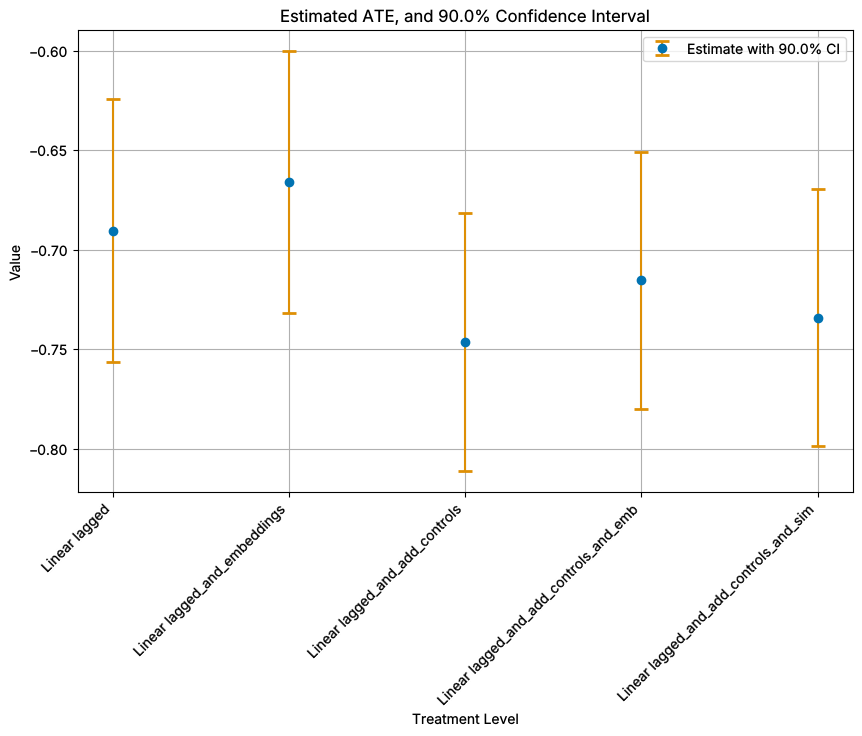

In [29]:
# Plotting
plt.figure(figsize=(10, 6))
# Plot Estimate with CI
plt.errorbar(
    df_base["model"],
    df_base["coef"],
    yerr=[df_base["coef"] - df_base["lower"], df_base["upper"] - df_base["coef"]],
    fmt="o",
    capsize=5,
    capthick=2,
    ecolor=palette[1],
    color=palette[0],
    label=f"Estimate with {round(confidence_level * 100, 1)}% CI",
    zorder=2,
)

plt.title(f"Estimated ATE, and {round(confidence_level * 100, 1)}% Confidence Interval")
plt.xlabel("Treatment Level")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_dir, f"linear_ate_estimates.png"))
plt.show()

In [30]:
df_base

,lower,upper,coef,model
0,-0.756093,-0.624438,-0.690266,Linear lagged
1,-0.731567,-0.600182,-0.665874,Linear lagged_and_embeddings
2,-0.811127,-0.681600,-0.746364,Linear lagged_and_add_controls
3,-0.779902,-0.650636,-0.715269,Linear lagged_and_add_controls_and_emb
4,-0.798488,-0.669656,-0.734072,Linear lagged_and_add_controls_and_sim


### DML Models

In [31]:
ml_g = LGBMRegressor(n_estimators=500, lr=0.02, random_state=42, verbose=-1)
ml_m = LGBMRegressor(n_estimators=500, lr=0.02, random_state=42, verbose=-1)


def r2(y_true, y_pred):
    subset = np.logical_not(np.isnan(y_true))
    return r2_score(y_true[subset], y_pred[subset])


def estimate_dml_model(controls):
    tab_dml_data = dml.DoubleMLClusterData(
        df_dynamic,
        y_col=outcome[0],
        d_cols=base_treatment,
        x_cols=controls,
        cluster_cols="ASIN",
    )

    np.random.seed(3141)
    tab_dml_obj = dml.DoubleMLPLR(tab_dml_data, ml_g, ml_m)
    tab_dml_obj.fit()

    tab_summary_df = summarize_dml(tab_dml_obj, level=confidence_level)
    ci_tab_dml = tab_summary_df[ci_names + ["coef"]]
    ci_tab_dml.columns = ["lower", "upper", "coef"]

    r2_scores = tab_dml_obj.evaluate_learners(metric=r2)
    print(
        f"R2 Outcome: {round(r2_scores['ml_l'][0, 0], 4)} R2 Treatment: {round(r2_scores['ml_m'][0, 0], 4)}\n"
    )

    return tab_dml_obj, ci_tab_dml

In [32]:
tab_dml_obj_embeddings, ci_tab_dml_embeddings = estimate_dml_model(
    controls=lag_1_vars + embeddings
)

         coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.612    0.043 -14.203    0.0 -0.683 -0.541
R2 Outcome: 0.8682 R2 Treatment: 0.9738



In [33]:
tab_dml_obj_add_controls, ci_tab_dml_add_controls = estimate_dml_model(
    controls=lag_1_vars + additional_controls
)

        coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.69    0.041 -16.812    0.0 -0.758 -0.623
R2 Outcome: 0.8991 R2 Treatment: 0.9775



In [34]:
tab_dml_obj_embeddings_add_controls, ci_tab_dml_embeddings_add_controls = (
    estimate_dml_model(controls=lag_1_vars + embeddings + additional_controls)
)

         coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.706    0.044 -16.066    0.0 -0.778 -0.634
R2 Outcome: 0.8942 R2 Treatment: 0.9755



In [35]:
tab_dml_obj_sim_add_controls, ci_tab_dml_sim_add_controls = estimate_dml_model(
    controls=lag_1_vars + controls_similarities + additional_controls
)

         coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.697    0.041 -17.061    0.0 -0.764  -0.63
R2 Outcome: 0.8992 R2 Treatment: 0.9771



In [36]:
tab_dml_obj_pca_add_controls, ci_tab_dml_pca_add_controls = estimate_dml_model(
    controls=lag_1_vars + controls_pca + additional_controls
)

         coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.694    0.042 -16.553    0.0 -0.763 -0.625
R2 Outcome: 0.901 R2 Treatment: 0.9771



### Visualization

In [37]:
ci_tab_dml_embeddings["model"] = "plr_embeddings"
ci_tab_dml_add_controls["model"] = "plr_add_controls"
ci_tab_dml_embeddings_add_controls["model"] = "plr_embeddings_add_controls"
ci_tab_dml_sim_add_controls["model"] = "plr_sim_add_controls"
ci_tab_dml_pca_add_controls["model"] = "plr_pca_add_controls"


df_averages = pd.concat(
    [
        ci_tab_dml_embeddings,
        ci_tab_dml_add_controls,
        ci_tab_dml_embeddings_add_controls,
        ci_tab_dml_sim_add_controls,
        ci_tab_dml_pca_add_controls,
    ],
    ignore_index=True,
)

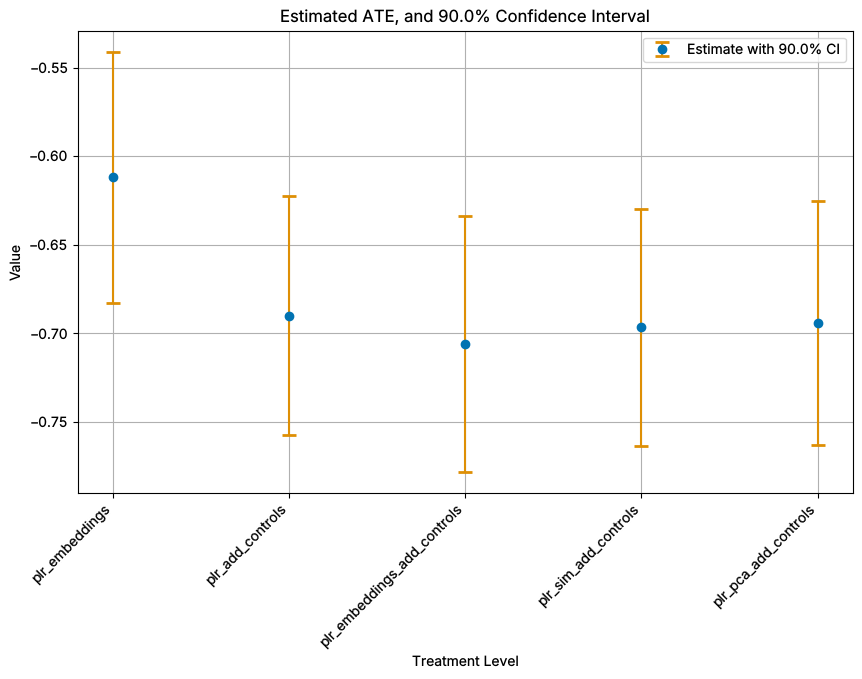

In [38]:
# Plotting
plt.figure(figsize=(10, 6))
# Plot Estimate with CI
plt.errorbar(
    df_averages["model"],
    df_averages["coef"],
    yerr=[
        df_averages["coef"] - df_averages["lower"],
        df_averages["upper"] - df_averages["coef"],
    ],
    fmt="o",
    capsize=5,
    capthick=2,
    ecolor=palette[1],
    color=palette[0],
    label=f"Estimate with {round(confidence_level * 100, 1)}% CI",
    zorder=2,
)

plt.title(f"Estimated ATE, and {round(confidence_level * 100, 1)}% Confidence Interval")
plt.xlabel("Treatment Level")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_dir, f"plr_ate_estimates.png"))
plt.show()

## GATEs

0
similarity_cluster_0     8022
similarity_cluster_1     9195
similarity_cluster_2     4108
similarity_cluster_3     5381
similarity_cluster_4    11335
dtype: int64


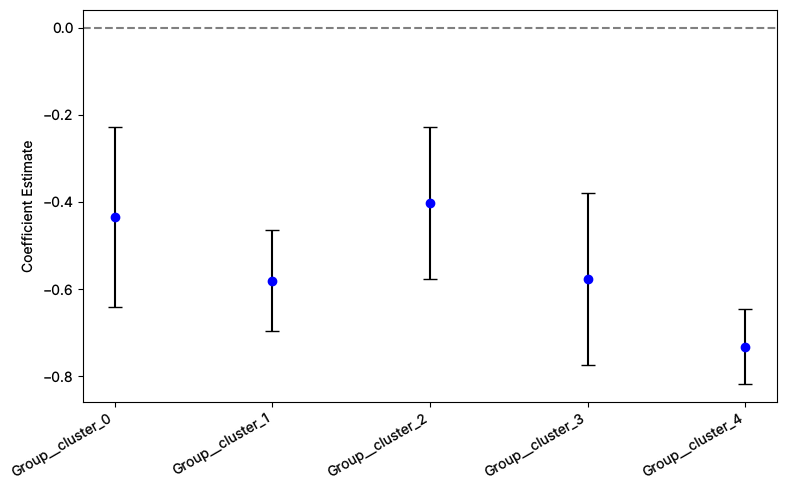

In [39]:
groups = pd.DataFrame(
    df_dynamic[
        [
            "similarity_cluster_0",
            "similarity_cluster_1",
            "similarity_cluster_2",
            "similarity_cluster_3",
            "similarity_cluster_4",
        ]
    ].idxmax(axis=1)
)

print(groups.groupby(0).size())
gates_0 = tab_dml_obj_embeddings.gate(groups)
gates_0_summ = gates_0.summary
gates_0_summ["err_lower"] = gates_0_summ["coef"] - gates_0_summ["[0.025"]
gates_0_summ["err_upper"] = gates_0_summ["0.975]"] - gates_0_summ["coef"]

# Positions on the x-axis
x_vals = range(len(gates_0_summ))

plt.figure(figsize=(8, 5))
plt.errorbar(
    x=x_vals,
    y=gates_0_summ["coef"],
    yerr=[gates_0_summ["err_lower"], gates_0_summ["err_upper"]],
    fmt="o",
    capsize=5,
    color="blue",
    ecolor="black",
)

# Draw a zero line for reference
plt.axhline(y=0, color="gray", linestyle="--")

# Customizing x-axis labels
plt.xticks(
    ticks=x_vals,
    labels=[gr.replace("similarity", "") for gr in gates_0_summ.index],
    rotation=30,
    ha="right",
)
plt.ylabel("Coefficient Estimate")
plt.tight_layout()
plt.show()

## CATEs

In [40]:
uniform_ci = True  # False | True

In [41]:
cate_controls = lag_1_vars + embeddings + additional_controls
cate_controls_interactions = cate_controls + interaction_vars

plr_obj = tab_dml_obj_embeddings_add_controls

In [42]:
import gc

gc.collect()

9522

In [43]:
cate_kwargs_val = {"cov_type": "cluster", "cov_kwds": {"groups": df_dynamic["ASIN"]}}

cate_models_polynomial = {
    "Linear Specification": None,
    "Linear Specification (Interactions)": None,
    "PLR Specification": None,
}

# Linear Models
cate_models_polynomial["Linear Specification"] = lin_model_cate(
    df=df_dynamic,
    outcome=outcome,
    basis=df_basis,
    treatment=base_treatment,
    controls=cate_controls,
    **cate_kwargs_val,
)

print(f"\nLinear Specification")
df_specification_1 = summarize_lin_model(
    cate_models_polynomial["Linear Specification"], level=confidence_level
)
print("=" * 80)  #

cate_models_polynomial["Linear Specification (Interactions)"] = lin_model_cate(
    df=df_dynamic,
    outcome=outcome,
    basis=df_basis,
    treatment=base_treatment,
    controls=cate_controls_interactions,
    **cate_kwargs_val,
)

print(f"\nLinear specification with interactions")
df_specification_2 = summarize_lin_model(
    cate_models_polynomial["Linear Specification (Interactions)"],
    level=confidence_level,
)
print("=" * 80)

# tabular DML model
cate_models_polynomial["PLR Specification"] = plr_obj.cate(df_basis, **cate_kwargs_val)

print(f"\nTabular DML PLR Specification")
df_specification_3 = summarize_lin_model(
    cate_models_polynomial["PLR Specification"].blp_model, level=confidence_level
)
print("=" * 80)


Linear Specification
                       coef  std err       t  P>|t|   5.0%  95.0%
intercept            -0.683    0.041 -16.515  0.000 -0.751 -0.615
Q_t-1                -0.197    0.045  -4.405  0.000 -0.270 -0.123
P_bb_t-1             -0.015    0.036  -0.419  0.675 -0.075  0.044
similarity_cluster_0 -0.512    1.991  -0.257  0.797 -3.788  2.764
similarity_cluster_1 -0.488    1.773  -0.275  0.783 -3.404  2.429
similarity_cluster_2 -0.305    1.846  -0.165  0.869 -3.341  2.731
similarity_cluster_3 -0.425    1.672  -0.254  0.800 -3.174  2.325
similarity_cluster_4 -1.095    2.558  -0.428  0.669 -5.302  3.112



Linear specification with interactions
                       coef  std err       t  P>|t|   5.0%  95.0%
intercept            -0.696    0.041 -16.846  0.000 -0.764 -0.628
Q_t-1                -0.208    0.044  -4.669  0.000 -0.281 -0.135
P_bb_t-1             -0.015    0.037  -0.412  0.680 -0.076  0.045
similarity_cluster_0 -0.316    2.000  -0.158  0.875 -3.606  2.974
similarity_cluster_1 -0.250    1.782  -0.140  0.888 -3.182  2.681
similarity_cluster_2 -0.068    1.855  -0.037  0.971 -3.119  2.983
similarity_cluster_3 -0.232    1.679  -0.138  0.890 -2.994  2.530
similarity_cluster_4 -0.783    2.571  -0.305  0.761 -5.011  3.445

Tabular DML PLR Specification
                       coef  std err       t  P>|t|   5.0%  95.0%
intercept            -0.694    0.046 -15.240  0.000 -0.769 -0.619
Q_t-1                -0.291    0.081  -3.569  0.000 -0.424 -0.157
P_bb_t-1             -0.008    0.025  -0.325  0.745 -0.049  0.033
similarity_cluster_0  2.739    2.271   1.206  0.228 -0.997  6.475
simil

In [44]:
cate_models_polynomial["Linear Specification (Interactions)"].summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.025
Model:                            OLS   Adj. R-squared (uncentered):              0.025
Method:                 Least Squares   F-statistic:                              61.17
Date:                Wed, 14 Oct 2026   Prob (F-statistic):                    2.60e-94
Time:                        02:42:45   Log-Likelihood:                         -20788.
No. Observations:               38041   AIC:                                  4.159e+04
Df Residuals:                   38033   BIC:                                  4.166e+04
Df Model:                           8                                                  
Covariance Type:              cluster                                                  
========================================================================================
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
intercept               -0.6959      0.041    -16.846      0.000      -0.777      -0.615
Q_t-1                   -0.2077      0.044     -4.669      0.000      -0.295      -0.121
P_bb_t-1                -0.0152      0.037     -0.412      0.680      -0.088       0.057
similarity_cluster_0    -0.3159      2.000     -0.158      0.875      -4.236       3.604
similarity_cluster_1    -0.2502      1.782     -0.140      0.888      -3.743       3.243
similarity_cluster_2    -0.0680      1.855     -0.037      0.971      -3.703       3.567
similarity_cluster_3    -0.2323      1.679     -0.138      0.890      -3.523       3.059
similarity_cluster_4    -0.7828      2.571     -0.305      0.761      -5.821       4.255
==============================================================================
Omnibus:                    12025.802   Durbin-Watson:                   2.003
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           692488.916
Skew:                           0.712   Prob(JB):                         0.00
Kurtosis:                      23.853   Cond. No.                         134.
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors are robust to cluster correlation (cluster)
"""

In [45]:
cate_models_polynomial["PLR Specification"].blp_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.031
Model:                            OLS   Adj. R-squared (uncentered):              0.031
Method:                 Least Squares   F-statistic:                              51.84
Date:                Wed, 14 Oct 2026   Prob (F-statistic):                    4.75e-80
Time:                        02:42:45   Log-Likelihood:                         -21130.
No. Observations:               38041   AIC:                                  4.228e+04
Df Residuals:                   38033   BIC:                                  4.234e+04
Df Model:                           8                                                  
Covariance Type:              cluster                                                  
========================================================================================
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
intercept               -0.6938      0.046    -15.240      0.000      -0.783      -0.605
Q_t-1                   -0.2906      0.081     -3.569      0.000      -0.450      -0.131
P_bb_t-1                -0.0080      0.025     -0.325      0.745      -0.056       0.040
similarity_cluster_0     2.7392      2.271      1.206      0.228      -1.713       7.191
similarity_cluster_1     2.0372      2.068      0.985      0.325      -2.016       6.091
similarity_cluster_2     2.4615      2.110      1.166      0.243      -1.675       6.598
similarity_cluster_3     2.2894      1.897      1.207      0.227      -1.428       6.007
similarity_cluster_4     2.8825      2.916      0.988      0.323      -2.833       8.598
==============================================================================
Omnibus:                    14442.949   Durbin-Watson:                   1.580
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           458448.671
Skew:                           1.198   Prob(JB):                         0.00
Kurtosis:                      19.837   Cond. No.                         228.
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors are robust to cluster correlation (cluster)
"""

In [46]:
latex_args = {
    "index": True,
    "float_format": "%.3f",
    "column_format": "lcccccc",
}

print(df_specification_1.to_latex(**latex_args))
print(df_specification_2.to_latex(**latex_args))
print(df_specification_3.to_latex(**latex_args))

\begin{tabular}{lcccccc}
\toprule
 & coef & std err & t & P>|t| & 5.0% & 95.0% \\
\midrule
intercept & -0.683 & 0.041 & -16.515 & 0.000 & -0.751 & -0.615 \\
Q_t-1 & -0.197 & 0.045 & -4.405 & 0.000 & -0.270 & -0.123 \\
P_bb_t-1 & -0.015 & 0.036 & -0.419 & 0.675 & -0.075 & 0.044 \\
similarity_cluster_0 & -0.512 & 1.991 & -0.257 & 0.797 & -3.788 & 2.764 \\
similarity_cluster_1 & -0.488 & 1.773 & -0.275 & 0.783 & -3.404 & 2.429 \\
similarity_cluster_2 & -0.305 & 1.846 & -0.165 & 0.869 & -3.341 & 2.731 \\
similarity_cluster_3 & -0.425 & 1.672 & -0.254 & 0.800 & -3.174 & 2.325 \\
similarity_cluster_4 & -1.095 & 2.558 & -0.428 & 0.669 & -5.302 & 3.112 \\
\bottomrule
\end{tabular}

\begin{tabular}{lcccccc}
\toprule
 & coef & std err & t & P>|t| & 5.0% & 95.0% \\
\midrule
intercept & -0.696 & 0.041 & -16.846 & 0.000 & -0.764 & -0.628 \\
Q_t-1 & -0.208 & 0.044 & -4.669 & 0.000 & -0.281 & -0.135 \\
P_bb_t-1 & -0.015 & 0.037 & -0.412 & 0.680 & -0.076 & 0.045 \\
similarity_cluster_0 & -0.316 & 2.00

In [47]:
summary_list = []
for model_name, model in cate_models_polynomial.items():
    if "Linear" in model_name:
        tmp_summary = summarize_lin_model(model, level=confidence_level)
    else:
        tmp_summary = summarize_lin_model(model.blp_model, level=confidence_level)
    for index, row in tmp_summary.iterrows():
        variable = index
        summary_list.append(
            {
                "model": model_name,
                "variable": variable,
                "coef": row["coef"],
                "Std.Err.": row["std err"],
                "lower": row[ci_names[0]],  # Adjusted to match the column name
                "upper": row[ci_names[1]],  # Adjusted to match the column name
            }
        )

cate_summary_df = pd.DataFrame(summary_list)

                       coef  std err       t  P>|t|   5.0%  95.0%
intercept            -0.683    0.041 -16.515  0.000 -0.751 -0.615
Q_t-1                -0.197    0.045  -4.405  0.000 -0.270 -0.123
P_bb_t-1             -0.015    0.036  -0.419  0.675 -0.075  0.044
similarity_cluster_0 -0.512    1.991  -0.257  0.797 -3.788  2.764
similarity_cluster_1 -0.488    1.773  -0.275  0.783 -3.404  2.429
similarity_cluster_2 -0.305    1.846  -0.165  0.869 -3.341  2.731
similarity_cluster_3 -0.425    1.672  -0.254  0.800 -3.174  2.325
similarity_cluster_4 -1.095    2.558  -0.428  0.669 -5.302  3.112
                       coef  std err       t  P>|t|   5.0%  95.0%
intercept            -0.696    0.041 -16.846  0.000 -0.764 -0.628
Q_t-1                -0.208    0.044  -4.669  0.000 -0.281 -0.135
P_bb_t-1             -0.015    0.037  -0.412  0.680 -0.076  0.045
similarity_cluster_0 -0.316    2.000  -0.158  0.875 -3.606  2.974
similarity_cluster_1 -0.250    1.782  -0.140  0.888 -3.182  2.681
similarity

In [48]:
cate_summary_df

,model,variable,coef,Std.Err.,lower,upper
0,Linear Specification,intercept,-0.683234,0.041371,-0.751284,-0.615184
1,Linear Specification,Q_t-1,-0.196574,0.044622,-0.269970,-0.123178
2,Linear Specification,P_bb_t-1,-0.015188,0.036241,-0.074800,0.044423
3,Linear Specification,similarity_cluster_0,-0.512143,1.991460,-3.787804,2.763518
4,Linear Specification,similarity_cluster_1,-0.487841,1.773154,-3.404419,2.428737
5,Linear Specification,similarity_cluster_2,-0.305043,1.845682,-3.340920,2.730835
6,Linear Specification,similarity_cluster_3,-0.424535,1.671583,-3.174044,2.324974
7,Linear Specification,similarity_cluster_4,-1.095092,2.557823,-5.302337,3.112152
8,Linear Specification (Interactions),intercept,-0.695942,0.041312,-0.763894,-0.627990
9,Linear Specification (Interactions),Q_t-1,-0.207686,0.044477,-0.280845,-0.134528


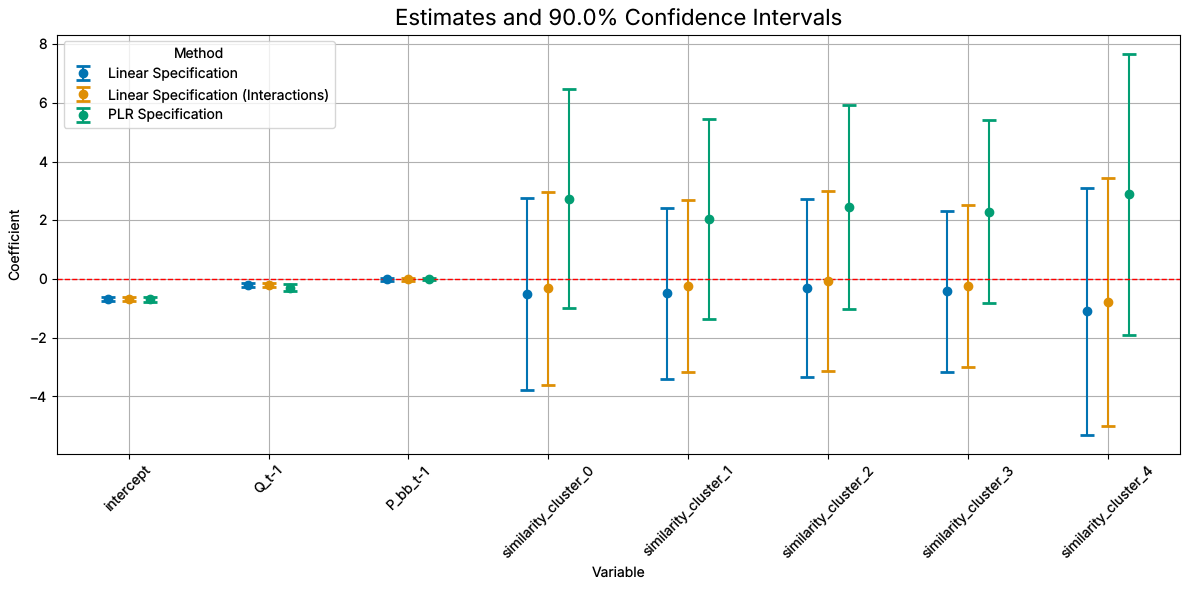

In [49]:
models = cate_summary_df["model"].unique()
variables = cate_summary_df["variable"].unique()
plt.figure(figsize=(12, 6))
bar_width = 0.15
x_positions = np.arange(len(variables))
for i, model in enumerate(models):
    df_model = cate_summary_df[cate_summary_df["model"] == model]
    if not df_model.empty:
        plt.errorbar(
            x_positions + i * bar_width,
            df_model["coef"],
            yerr=[
                df_model["coef"] - df_model["lower"],
                df_model["upper"] - df_model["coef"],
            ],
            fmt="o",
            label=model,
            capsize=5,
            capthick=2,
            ecolor=palette[i % len(palette)],
            color=palette[i % len(palette)],
            zorder=2,
        )
plt.xticks(x_positions + (len(models) - 1) * bar_width / 2, variables, rotation=45)
plt.axhline(0, color="red", linestyle="--", linewidth=1)
plt.title(f"Estimates and {ci_level_name} Confidence Intervals", fontsize=16)
plt.xlabel("Variable")
plt.ylabel("Coefficient")
plt.legend(title="Method")
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"cluster_and_level_cate_estimates.png"))
plt.show()

### $R^2$

In [50]:
alpha_x_lin = cate_models_polynomial["Linear Specification"].predict(df_basis)
alpha_x_lin_interactions = cate_models_polynomial[
    "Linear Specification (Interactions)"
].predict(df_basis)
alpha_x_plr = cate_models_polynomial["PLR Specification"].blp_model.predict(df_basis)


print("Linear Specification")
model_lin_emb = sm.OLS(alpha_x_lin, sm.add_constant(df_dynamic[embeddings])).fit()
model_lin_sim = sm.OLS(
    alpha_x_lin, sm.add_constant(df_dynamic[controls_similarities])
).fit()
model_lin_lvl = sm.OLS(alpha_x_lin, sm.add_constant(df_dynamic[lag_1_vars])).fit()

print("Variance explained by embeddings: ", model_lin_emb.rsquared)
print("Variance explained by similarities: ", model_lin_sim.rsquared)
print("Variance explained by lagged variables: ", model_lin_lvl.rsquared)

print("Linear Specification with interactions")
model_lin_interactions_emb = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[embeddings])
).fit()
model_lin_interactions_sim = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[controls_similarities])
).fit()
model_lin_interactions_lvl = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[lag_1_vars])
).fit()
print("Variance explained by embeddings: ", model_lin_interactions_emb.rsquared)
print("Variance explained by similarities: ", model_lin_interactions_sim.rsquared)
print("Variance explained by lagged variables: ", model_lin_interactions_lvl.rsquared)

print("PLR Specification")
model_plr_emb = sm.OLS(alpha_x_plr, sm.add_constant(df_dynamic[embeddings])).fit()
model_plr_sim = sm.OLS(
    alpha_x_plr, sm.add_constant(df_dynamic[controls_similarities])
).fit()
model_plr_lvl = sm.OLS(alpha_x_plr, sm.add_constant(df_dynamic[lag_1_vars])).fit()
print("Variance explained by embeddings: ", model_plr_emb.rsquared)
print("Variance explained by similarities: ", model_plr_sim.rsquared)
print("Variance explained by lagged variables: ", model_plr_lvl.rsquared)

Linear Specification


Variance explained by embeddings:  0.6653573892644329
Variance explained by similarities:  0.4137914857564088
Variance explained by lagged variables:  0.6781241166392422
Linear Specification with interactions


Variance explained by embeddings:  0.6502768414465272
Variance explained by similarities:  0.38759675900546575
Variance explained by lagged variables:  0.6985348380263551
PLR Specification


Variance explained by embeddings:  0.5803551237600519
Variance explained by similarities:  0.26750146058846935
Variance explained by lagged variables:  0.7652694700505673


## $\Chi^2$ Test

In [51]:
# select index with cluster similarity
cluster_treatment_ids = [
    i for i, variable in enumerate(df_basis.columns) if "similarity_cluster" in variable
]
cluster_treatment_ids

[3, 4, 5, 6, 7]

In [52]:
lin_p_val = chi2_test(
    cate_models_polynomial["Linear Specification"], cluster_treatment_ids
)
lin_interactions_p_val = chi2_test(
    cate_models_polynomial["Linear Specification (Interactions)"], cluster_treatment_ids
)
tab_dml_p_val = chi2_test(
    cate_models_polynomial["PLR Specification"], cluster_treatment_ids
)

print(f"Linear Specification p-value: {lin_p_val} (sample size: {len(df_dynamic)})")
print(
    f"Linear Specification (Interactions) p-value: {lin_interactions_p_val} (sample size: {len(df_dynamic)})"
)
print(f"PLR Specification p-value: {tab_dml_p_val} (sample size: {len(df_dynamic)})")

Linear Specification p-value: 0.013832498483810074 (sample size: 38041)
Linear Specification (Interactions) p-value: 0.01359820210271745 (sample size: 38041)
PLR Specification p-value: 0.006643550321333125 (sample size: 38041)


In [53]:
het_ids = [1, 2, 3, 4, 5, 6, 7]

lin_p_val = chi2_test(cate_models_polynomial["Linear Specification"], het_ids)
lin_interactions_p_val = chi2_test(
    cate_models_polynomial["Linear Specification (Interactions)"], het_ids
)
tab_dml_p_val = chi2_test(cate_models_polynomial["PLR Specification"], het_ids)

print(f"Linear Specification p-value: {lin_p_val} (sample size: {len(df_dynamic)})")
print(
    f"Linear Specification (Interactions) p-value: {lin_interactions_p_val} (sample size: {len(df_dynamic)})"
)
print(f"PLR Specification p-value: {tab_dml_p_val} (sample size: {len(df_dynamic)})")

Linear Specification p-value: 3.877452086076261e-06 (sample size: 38041)
Linear Specification (Interactions) p-value: 1.6006731954343323e-06 (sample size: 38041)
PLR Specification p-value: 2.486220852226939e-05 (sample size: 38041)


## Sorted Effects

In [54]:
treatment_ids = [0, 1, 2] + cluster_treatment_ids
df_basis_sorted = df_basis.iloc[:, treatment_ids]  # .join(df_dynamic[["ASIN", "date"]])

In [55]:
df_basis_sorted

,intercept,Q_t-1,P_bb_t-1,similarity_cluster_0,similarity_cluster_1,similarity_cluster_2,similarity_cluster_3,similarity_cluster_4
0,1.0,0.305280,0.463601,-0.146555,-0.116269,0.169582,-0.002445,0.051579
1,1.0,0.272505,0.653600,-0.146555,-0.116269,0.169582,-0.002445,0.051579
2,1.0,0.036240,0.687961,-0.146555,-0.116269,0.169582,-0.002445,0.051579
3,1.0,0.025283,0.636881,-0.146555,-0.116269,0.169582,-0.002445,0.051579
4,1.0,-0.051370,0.556816,-0.146555,-0.116269,0.169582,-0.002445,0.051579
...,...,...,...,...,...,...,...,...
38036,1.0,0.009068,0.478593,0.101415,0.269461,-0.010980,0.085172,-0.312814
38037,1.0,-0.393270,-0.753352,-0.056767,-0.067838,-0.039419,-0.105925,0.206408
38038,1.0,-0.277916,-0.753352,-0.054619,-0.067285,0.007179,-0.088707,0.159267
38039,1.0,1.267533,-1.535804,0.633464,-0.233925,-0.187120,-0.250090,-0.019039


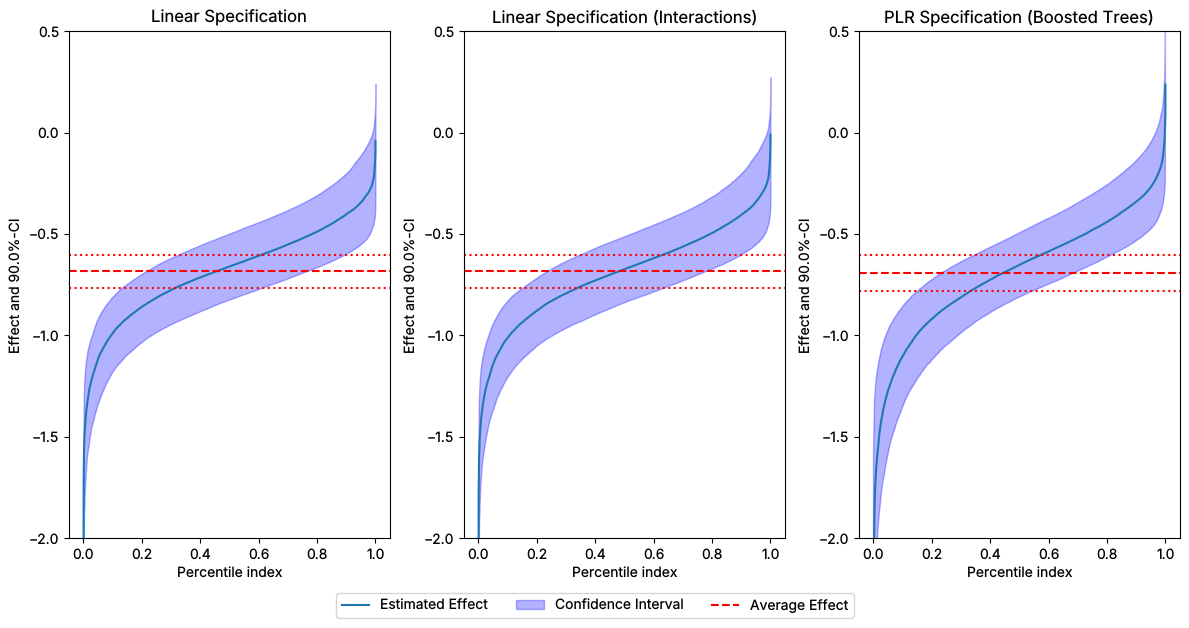

In [56]:
uniform_ci = False

plt.rcParams["figure.figsize"] = (
    15.0,
    7.5,
)  # Adjusted the figure size for side-by-side plots
# Determine the number of models to plot
num_plots = 1
# Create subplots with cate_vars as rows and models as columns
fig, axs = plt.subplots(nrows=num_plots, ncols=3, figsize=(12, 6 * num_plots))
# If there's only one model, axs won't be a list, so wrap it in a list
if num_plots == 1:
    axs = np.array([axs, axs])  # Create a 2-column array


# Linear model
df_lin_ci_pointwise = predict_cate(
    cate_models_polynomial["Linear Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_lin_ci_pointwise_sorted = df_lin_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_lin_ci_uniform = predict_cate(
    cate_models_polynomial["Linear Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_lin_ci_uniform_sorted = df_lin_ci_uniform.apply(
    lambda x: x.sort_values().values, axis=0
)
lm_intercept = cate_models_polynomial["Linear Specification"].params["intercept"]
lm_intercept_ci = (
    cate_models_polynomial["Linear Specification"].conf_int().loc["intercept"]
)

# Tabular DML model
df_tab_dml_ci_pointwise = predict_cate(
    cate_models_polynomial["Linear Specification (Interactions)"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_tab_dml_ci_pointwise_sorted = df_tab_dml_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_tab_dml_ci_joint = predict_cate(
    cate_models_polynomial["Linear Specification (Interactions)"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_tab_dml_ci_joint_sorted = df_tab_dml_ci_joint.apply(
    lambda x: x.sort_values().values, axis=0
)

tab_dml_intercept = cate_models_polynomial["Linear Specification"].params["intercept"]
tab_dml_intercept_ci = (
    cate_models_polynomial["Linear Specification"].conf_int().loc["intercept"]
)

# PLR Model
df_deep_dml_ci_pointwise = predict_cate(
    cate_models_polynomial["PLR Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_deep_dml_ci_pointwise_sorted = df_deep_dml_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_deep_dml_ci_joint = predict_cate(
    cate_models_polynomial["PLR Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_deep_dml_ci_joint_sorted = df_deep_dml_ci_joint.apply(
    lambda x: x.sort_values().values, axis=0
)
deep_dml_intercept = cate_models_polynomial["PLR Specification"].blp_model.params[
    "intercept"
]
deep_dml_intercept_ci = (
    cate_models_polynomial["PLR Specification"].blp_model.conf_int().loc["intercept"]
)

# Calculate the y-axis limits for this row
y_min = min(
    df_lin_ci_pointwise[ci_names[0]].min(),
    df_lin_ci_uniform[ci_names[0]].min(),
    df_tab_dml_ci_pointwise[ci_names[0]].min(),
    df_tab_dml_ci_joint[ci_names[0]].min(),
    df_deep_dml_ci_pointwise[ci_names[0]].min(),
    df_deep_dml_ci_joint[ci_names[0]].min(),
)
y_max = max(
    df_lin_ci_pointwise[ci_names[1]].max(),
    df_lin_ci_uniform[ci_names[1]].max(),
    df_tab_dml_ci_pointwise[ci_names[1]].max(),
    df_tab_dml_ci_joint[ci_names[1]].max(),
    df_deep_dml_ci_pointwise[ci_names[1]].max(),
    df_deep_dml_ci_joint[ci_names[1]].max(),
)

# further adjust y-axis limits
y_min = max(y_min, -2)
y_max = min(y_max, 0.5)
percentiles_idx = np.linspace(0, 1, df_dynamic.shape[0])
percentiles_idx_full = np.linspace(0, 1, df_dynamic.shape[0])
# Plot on the first column
i = 0
ax0 = axs[i, 0]
ax0.plot(
    percentiles_idx_full, df_lin_ci_pointwise_sorted["effect"], label="Estimated Effect"
)
ax0.fill_between(
    percentiles_idx_full,
    df_lin_ci_pointwise_sorted[ci_names[0]],
    df_lin_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax0.fill_between(
        percentiles_idx_full,
        df_lin_ci_uniform_sorted[ci_names[0]],
        df_lin_ci_uniform_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax0.axhline(y=lm_intercept, color="r", linestyle="--", label="ATE")
ax0.axhline(y=lm_intercept_ci[0], color="r", linestyle="dotted")
ax0.axhline(y=lm_intercept_ci[1], color="r", linestyle="dotted")
ax0.set_title("Linear Specification")
ax0.set_xlabel("Percentile index")
ax0.set_ylabel(f"Effect and {ci_level_name}-CI")
ax0.set_ylim(y_min, y_max)
ax1 = axs[i, 1]
ax1.plot(
    percentiles_idx_full,
    df_tab_dml_ci_pointwise_sorted["effect"],
    label="Estimated Effect",
)
ax1.fill_between(
    percentiles_idx_full,
    df_tab_dml_ci_pointwise_sorted[ci_names[0]],
    df_tab_dml_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax1.fill_between(
        percentiles_idx_full,
        df_tab_dml_ci_joint_sorted[ci_names[0]],
        df_tab_dml_ci_joint_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax1.axhline(y=tab_dml_intercept, color="r", linestyle="--", label="Average Effect")
ax1.axhline(y=tab_dml_intercept_ci[0], color="r", linestyle="dotted")
ax1.axhline(y=tab_dml_intercept_ci[1], color="r", linestyle="dotted")
ax1.set_title("Linear Specification (Interactions)")
ax1.set_xlabel("Percentile index")
ax1.set_ylabel(f"Effect and {ci_level_name}-CI")
ax1.set_ylim(y_min, y_max)

ax2 = axs[i, 2]
ax2.plot(
    percentiles_idx_full,
    df_deep_dml_ci_pointwise_sorted["effect"],
    label="Estimated Effect",
)
ax2.fill_between(
    percentiles_idx_full,
    df_deep_dml_ci_pointwise_sorted[ci_names[0]],
    df_deep_dml_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax2.fill_between(
        percentiles_idx_full,
        df_deep_dml_ci_joint_sorted[ci_names[0]],
        df_deep_dml_ci_joint_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax2.axhline(y=deep_dml_intercept, color="r", linestyle="--", label="Average Effect")
ax2.axhline(y=deep_dml_intercept_ci[0], color="r", linestyle="dotted")
ax2.axhline(y=deep_dml_intercept_ci[1], color="r", linestyle="dotted")

ax2.set_title("PLR Specification (Boosted Trees)")
ax2.set_xlabel("Percentile index")
ax2.set_ylabel(f"Effect and {ci_level_name}-CI")
ax2.set_ylim(y_min, y_max)

# Create a single legend for all plots and place it at the lower center
handles, labels = axs[
    -1, 1 
].get_legend_handles_labels()  # Collect handles and labels from the last subplot
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.05), ncol=4)
# Adjust layout to make space for the legend
plt.tight_layout(rect=[0, 0.0, 1, 1])  # Leave space at the bottom for the legend

# Save the figure with tight bounding box to include the legend
plt.savefig(os.path.join(output_dir, "cluster_sorted_effects.png"), bbox_inches="tight")
plt.show()

In [57]:
quantiles = np.arange(start=0.01, stop=1, step=0.01)
m = len(quantiles)
pes = df_tab_dml_ci_pointwise["effect"]
spes = df_tab_dml_ci_pointwise["effect"].quantile(quantiles).values
spes

array([-1.39542851, -1.29606842, -1.23412166, -1.18776503, -1.14138793,
       -1.10688053, -1.08005229, -1.05425473, -1.02940904, -1.01091368,
       -0.99242816, -0.97709859, -0.96154616, -0.94721065, -0.93497338,
       -0.92280786, -0.91103881, -0.89896892, -0.88852487, -0.87775524,
       -0.86731121, -0.85697966, -0.84674948, -0.83791757, -0.82969883,
       -0.82186891, -0.81411015, -0.80590314, -0.79928344, -0.79183624,
       -0.78478792, -0.77804069, -0.77160071, -0.76501696, -0.75824812,
       -0.75200757, -0.74581936, -0.7399532 , -0.73392766, -0.72825125,
       -0.72251349, -0.71679474, -0.71102852, -0.7057679 , -0.70015462,
       -0.69464434, -0.68964603, -0.68399984, -0.6784897 , -0.67336461,
       -0.66736944, -0.66202572, -0.65688748, -0.65173135, -0.64601498,
       -0.64081429, -0.63510927, -0.62968107, -0.6241262 , -0.61885637,
       -0.61327312, -0.60789867, -0.60244448, -0.59711029, -0.59150448,
       -0.58563871, -0.57978891, -0.57427676, -0.56802219, -0.56

# Sensitivity Analysis

Sensitivity analysis for ATE with PLM model.

In [58]:
plr_obj.sensitivity_analysis(
    cf_y=0.03,
    cf_d=0.03,
    rho=1.0,
    level=0.9,
    null_hypothesis=0.0
)
print(plr_obj.sensitivity_summary)

================== Sensitivity Analysis ==================

------------------ Scenario          ------------------
Significance Level: level=0.9
Sensitivity parameters: cf_y=0.03; cf_d=0.03, rho=1.0

------------------ Bounds with CI    ------------------
        CI lower  theta lower     theta  theta upper  CI upper
P_bb_t -0.893101    -0.838802 -0.705951    -0.573101 -0.514316

------------------ Robustness Values ------------------
        H_0    RV (%)    RVa (%)
P_bb_t  0.0  14.92928  13.531008


In [59]:
sigma_l = tab_dml_obj_embeddings_add_controls.sensitivity_elements["sigma2"]
sigma_s = tab_dml_obj_embeddings.sensitivity_elements["sigma2"]

nu_l = tab_dml_obj_embeddings_add_controls.sensitivity_elements["nu2"]
nu_s = tab_dml_obj_embeddings.sensitivity_elements["nu2"]

delta_theta = tab_dml_obj_embeddings_add_controls.coef - tab_dml_obj_embeddings.coef

rho_hat = np.abs(delta_theta) / (np.sqrt(sigma_s - sigma_l) * np.sqrt(nu_l - nu_s)).squeeze()

print(f"Implied rho: {rho_hat}")

Implied rho: [0.16482157]


In [60]:
r2_scores_l = tab_dml_obj_embeddings_add_controls.evaluate_learners(metric=r2)
print(
    f"R2 Outcome: {r2_scores_l['ml_l'][0, 0]} R2 Treatment: {r2_scores_l['ml_m'][0, 0]}\n"
)

r2_y_l = r2_scores_l["ml_l"][0, 0]
r2_d_l = r2_scores_l["ml_m"][0, 0]


r2_scores_s = tab_dml_obj_embeddings.evaluate_learners(metric=r2)
print(
    f"R2 Outcome: {r2_scores_s['ml_l'][0, 0]} R2 Treatment: {r2_scores_s['ml_m'][0, 0]}\n"
)

r2_y_s = r2_scores_s["ml_l"][0, 0]
r2_d_s = r2_scores_s["ml_m"][0, 0]

R2 Outcome: 0.8942288081868626 R2 Treatment: 0.9755354269703521

R2 Outcome: 0.8681994936537599 R2 Treatment: 0.9737950470691331



In [61]:
partial_r2_y = (r2_y_l - r2_y_s) / (1 - r2_y_s)
partial_r2_d = (r2_d_l - r2_d_s) / (1 - r2_d_s)

print(f"Partial R2 Outcome: {partial_r2_y}")
print(f"Partial R2 Treatment: {partial_r2_d}")

Partial R2 Outcome: 0.1974902468487003
Partial R2 Treatment: 0.06641415864437612


In [62]:
# NEW CHECK

K = rho_hat * np.sqrt(partial_r2_y * partial_r2_d / (1 - partial_r2_d))
scaled_implied_RV = (-K**2 + K*np.sqrt(K**2 + 4)) / 2

print(scaled_implied_RV.round(4))

[0.0193]


In [63]:
# Check

np.sqrt(scaled_implied_RV * scaled_implied_RV / (1 - scaled_implied_RV))

array([0.0195362])

In [64]:
sensitivity_res = dict()

rho_vec = [1.0, 0.5, 0.2]
scenarios = [(0.01, 0.01), (0.025, 0.025), (0.05, 0.05)]

theta_lower = []
theta_upper = []
ci_lower = []   
ci_upper = []
R2_y = []
R2_d = []
rho_list = []

for rho in rho_vec:
    for cf_y, cf_d in scenarios:
        plr_obj.sensitivity_analysis(
            cf_y=cf_y,
            cf_d=cf_d,
            rho=rho,
            level=confidence_level,
            null_hypothesis=0.0
        )
        theta_lower.append(plr_obj.sensitivity_params["theta"]["lower"][0])
        theta_upper.append(plr_obj.sensitivity_params["theta"]["upper"][0])
        ci_lower.append(plr_obj.sensitivity_params["ci"]["lower"][0])
        ci_upper.append(plr_obj.sensitivity_params["ci"]["upper"][0])
        R2_y.append(cf_y)
        R2_d.append(cf_d)
        rho_list.append(rho)


In [65]:
df_sensitivity = pd.DataFrame({
    "theta": plr_obj.coef[0],
    "theta_lower": theta_lower,
    "theta_upper": theta_upper,
    "ci_lower": ci_lower,
    "ci_upper": ci_upper,
    "R2_y": R2_y,
    "R2_d": R2_d,
    "rho": rho_list,
})
df_sensitivity.head()

,theta,theta_lower,theta_upper,ci_lower,ci_upper,R2_y,R2_d,rho
0,-0.705951,-0.749785,-0.662117,-0.805381,-0.605036,0.010,0.010,1.0
1,-0.705951,-0.816376,-0.595527,-0.870981,-0.537189,0.025,0.025,1.0
2,-0.705951,-0.929687,-0.482215,-0.982899,-0.421506,0.050,0.050,1.0
3,-0.705951,-0.727868,-0.684034,-0.783817,-0.627343,0.010,0.010,0.5
4,-0.705951,-0.761163,-0.650739,-0.816582,-0.593451,0.025,0.025,0.5


In [66]:
scenario_names = ["mild", "medium", "strong"]

latex_args = {
    "index": False,
    "float_format": "%.3f",
    "column_format": "lcccccc",
    "escape": False,  # Allow LaTeX in column names
}

ci_lower_label = f"$[ {{{100*(1-confidence_level):.1f}}}\\% $"
ci_upper_label = f"${{{100*(confidence_level):.1f}}}\\% ]$"

for rho_val in rho_vec:
    df_rho = df_sensitivity[df_sensitivity["rho"] == rho_val].copy()
    # Add scenario column with names
    df_rho["Scenario ($R^2_Y$, $R^2_D$)"] = [
        f"{name} $({str(r2y).lstrip('0')}, {str(r2d).lstrip('0')})$"
        for name, r2y, r2d in zip(scenario_names, df_rho["R2_y"], df_rho["R2_d"])
    ]
    # Rename columns for LaTeX
    df_rho = df_rho.rename(
        columns={
            "theta": r"$\theta$",
            "theta_lower": r"$\theta_-$",
            "theta_upper": r"$\theta_+$",
            "ci_lower": ci_lower_label,
            "ci_upper": ci_upper_label,
        }
    )
    # Reorder columns as requested
    df_rho = df_rho[
        [
            "Scenario ($R^2_Y$, $R^2_D$)",
            ci_lower_label,
            r"$\theta_-$",
            r"$\theta$",
            r"$\theta_+$",
            ci_upper_label,
        ]
    ]
    caption = (
        f"Sensitivity analysis for $\\rho={rho_val}$: "
    )
    latex_str = df_rho.to_latex(
        caption=caption,
        label=f"tab:sensitivity_rho_{str(rho_val).replace('.', '')}",
        **latex_args,
    )
    # Insert \hline\hline after \begin{tabular} and replace \toprule/\bottomrule
    latex_str = latex_str.replace("\\toprule", "\\hline\\hline")
    latex_str = latex_str.replace("\\midrule", "\\midrule")
    latex_str = latex_str.replace("\\bottomrule", "\\hline\\hline")
    latex_str = latex_str.replace("\\begin{table}", "\\begin{table}[h]\n\\centering")
    print(latex_str)

\begin{table}[h]
\centering
\caption{Sensitivity analysis for $\rho=1.0$: }
\label{tab:sensitivity_rho_10}
\begin{tabular}{lcccccc}
\hline\hline
Scenario ($R^2_Y$, $R^2_D$) & $[ {10.0}\% $ & $\theta_-$ & $\theta$ & $\theta_+$ & ${90.0}\% ]$ \\
\midrule
mild $(.01, .01)$ & -0.805 & -0.750 & -0.706 & -0.662 & -0.605 \\
medium $(.025, .025)$ & -0.871 & -0.816 & -0.706 & -0.596 & -0.537 \\
strong $(.05, .05)$ & -0.983 & -0.930 & -0.706 & -0.482 & -0.422 \\
\hline\hline
\end{tabular}
\end{table}

\begin{table}[h]
\centering
\caption{Sensitivity analysis for $\rho=0.5$: }
\label{tab:sensitivity_rho_05}
\begin{tabular}{lcccccc}
\hline\hline
Scenario ($R^2_Y$, $R^2_D$) & $[ {10.0}\% $ & $\theta_-$ & $\theta$ & $\theta_+$ & ${90.0}\% ]$ \\
\midrule
mild $(.01, .01)$ & -0.784 & -0.728 & -0.706 & -0.684 & -0.627 \\
medium $(.025, .025)$ & -0.817 & -0.761 & -0.706 & -0.651 & -0.593 \\
strong $(.05, .05)$ & -0.872 & -0.818 & -0.706 & -0.594 & -0.536 \\
\hline\hline
\end{tabular}
\end{table}

\begin

# Export of Key Results

Collects the main estimates of this notebook in `output_dir` for the comparison across embeddings (`04_evaluation_gemma_comparison.ipynb`).

In [67]:
import json

key_results = {
    "embedding_source": embedding_source,
    "modality": modality if embedding_source != "finetuned" else "txtimg",
    "emb_dim": n_embeddings,
    "dataset": dataframe_name,
    "n_obs": int(len(df_dynamic)),
    "n_products": int(df_dynamic["ASIN"].nunique()),
}

# Linear models (ATE)
ci_linear_interactions["model"] = "Linear interactions"
df_linear = pd.concat([df_base, ci_linear_interactions], ignore_index=True)
df_linear.to_csv(os.path.join(output_dir, "linear_ate_estimates.csv"), index=False)

# PLR models (ATE) and learner R^2
plr_objects = {
    "plr_embeddings": tab_dml_obj_embeddings,
    "plr_add_controls": tab_dml_obj_add_controls,
    "plr_embeddings_add_controls": tab_dml_obj_embeddings_add_controls,
    "plr_sim_add_controls": tab_dml_obj_sim_add_controls,
    "plr_pca_add_controls": tab_dml_obj_pca_add_controls,
}
df_plr = df_averages.copy()
for model_name, obj in plr_objects.items():
    r2_scores = obj.evaluate_learners(metric=r2)
    df_plr.loc[df_plr["model"] == model_name, "std_err"] = obj.se[0]
    df_plr.loc[df_plr["model"] == model_name, "r2_outcome"] = r2_scores["ml_l"][0, 0]
    df_plr.loc[df_plr["model"] == model_name, "r2_treatment"] = r2_scores["ml_m"][0, 0]
df_plr.to_csv(os.path.join(output_dir, "plr_ate_estimates.csv"), index=False)
df_plr

,lower,upper,coef,model,std_err,r2_outcome,r2_treatment
0,-0.682783,-0.541050,-0.611916,plr_embeddings,0.043084,0.868199,0.973795
1,-0.757775,-0.622714,-0.690244,plr_add_controls,0.041056,0.899101,0.977486
2,-0.778229,-0.633674,-0.705951,plr_embeddings_add_controls,0.043942,0.894229,0.975535
3,-0.763982,-0.629621,-0.696802,plr_sim_add_controls,0.040843,0.899156,0.977052
4,-0.763140,-0.625187,-0.694164,plr_pca_add_controls,0.041935,0.900994,0.977075


In [68]:
# GATEs by most similar cluster
df_gates = gates_0_summ.copy()
group_sizes = groups.groupby(0).size()
group_sizes.index = "Group_" + group_sizes.index.astype(str)  # labels used by DoubleMLPLR.gate()
df_gates["n_obs"] = group_sizes.reindex(df_gates.index).values
assert df_gates["n_obs"].notna().all()
df_gates.to_csv(os.path.join(output_dir, "gate_estimates.csv"))

# CATE (best linear predictor) coefficients
cate_summary_df.to_csv(os.path.join(output_dir, "cate_estimates.csv"), index=False)

# Chi^2 tests
chi2_rows = []
for model_name, model in cate_models_polynomial.items():
    chi2_rows.append(
        {
            "model": model_name,
            "p_value_clusters": chi2_test(model, cluster_treatment_ids),
            "p_value_heterogeneity": chi2_test(model, het_ids),
        }
    )
df_chi2 = pd.DataFrame(chi2_rows)
df_chi2.to_csv(os.path.join(output_dir, "chi2_tests.csv"), index=False)

# Variance of the CATE explained by embeddings, similarities and lagged variables
df_var_explained = pd.DataFrame(
    {
        "Linear Specification": [model_lin_emb.rsquared, model_lin_sim.rsquared, model_lin_lvl.rsquared],
        "Linear Specification (Interactions)": [
            model_lin_interactions_emb.rsquared,
            model_lin_interactions_sim.rsquared,
            model_lin_interactions_lvl.rsquared,
        ],
        "PLR Specification": [model_plr_emb.rsquared, model_plr_sim.rsquared, model_plr_lvl.rsquared],
    },
    index=["embeddings", "similarities", "lagged variables"],
)
df_var_explained.to_csv(os.path.join(output_dir, "cate_variance_explained.csv"))
df_chi2

,model,p_value_clusters,p_value_heterogeneity
0,Linear Specification,0.013832,0.000004
1,Linear Specification (Interactions),0.013598,0.000002
2,PLR Specification,0.006644,0.000025


In [69]:
# Per-observation CATEs (as in ../output/04_evaluation/sorted_effects.csv)
df_sorted_effects = df_dynamic[["ASIN", "date"]].copy()
df_sorted_effects["SortEff_lin"] = df_lin_ci_pointwise["effect"].values
df_sorted_effects["SortEff_tab_dml"] = df_tab_dml_ci_pointwise["effect"].values
df_sorted_effects["SortEff_deep_dml"] = df_deep_dml_ci_pointwise["effect"].values
df_sorted_effects.to_csv(os.path.join(output_dir, "sorted_effects.csv"), index=False)

# Sensitivity analysis
df_sensitivity.to_csv(os.path.join(output_dir, "sensitivity_analysis.csv"), index=False)
plr_obj.sensitivity_analysis(cf_y=0.03, cf_d=0.03, rho=1.0, level=0.9, null_hypothesis=0.0)
key_results["sensitivity"] = {
    "theta": float(plr_obj.coef[0]),
    "theta_lower_cf003": float(plr_obj.sensitivity_params["theta"]["lower"][0]),
    "theta_upper_cf003": float(plr_obj.sensitivity_params["theta"]["upper"][0]),
    "ci_lower_cf003": float(plr_obj.sensitivity_params["ci"]["lower"][0]),
    "ci_upper_cf003": float(plr_obj.sensitivity_params["ci"]["upper"][0]),
    "rv": float(plr_obj.sensitivity_params["rv"][0]),
    "rva": float(plr_obj.sensitivity_params["rva"][0]),
    "implied_rho": float(np.squeeze(rho_hat)),
    "partial_r2_outcome": float(partial_r2_y),
    "partial_r2_treatment": float(partial_r2_d),
    "scaled_implied_rv": float(np.squeeze(scaled_implied_RV)),
}
key_results["sorted_effects_quantiles"] = {
    col: df_sorted_effects[col].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(6).tolist()
    for col in ["SortEff_lin", "SortEff_tab_dml", "SortEff_deep_dml"]
}
with open(os.path.join(output_dir, "key_results.json"), "w") as f:
    json.dump(key_results, f, indent=2)
print(json.dumps(key_results, indent=2))

{
  "embedding_source": "embeddinggemma2",
  "modality": "txtimg",
  "emb_dim": 768,
  "dataset": "dataset_gemma_txtimg_dim768",
  "n_obs": 38041,
  "n_products": 3708,
  "sensitivity": {
    "theta": -0.7059512179359988,
    "theta_lower_cf003": -0.8388016269894334,
    "theta_upper_cf003": -0.5731008088825642,
    "ci_lower_cf003": -0.8931013758190209,
    "ci_upper_cf003": -0.5143163884212304,
    "rv": 0.14929280269047696,
    "rva": 0.13531007650154306,
    "implied_rho": 0.16482156539636614,
    "partial_r2_outcome": 0.1974902468487003,
    "partial_r2_treatment": 0.06641415864437612,
    "scaled_implied_rv": 0.01934629946086223
  },
  "sorted_effects_quantiles": {
    "SortEff_lin": [
      -1.11544,
      -0.814059,
      -0.659888,
      -0.521245,
      -0.344352
    ],
    "SortEff_tab_dml": [
      -1.141388,
      -0.829699,
      -0.673365,
      -0.5302,
      -0.341795
    ],
    "SortEff_deep_dml": [
      -1.272161,
      -0.859612,
      -0.651293,
      -0.479245,
 